# SPY-cash targeting check

This notebook checks daily volatility-targeting weights, state, trading frictions, execution timing, and portfolio compounding on the canonical dataset.

In [1]:
import sys
from dataclasses import replace
from math import sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")

from backtest import BacktestConfig, build_ledger
from backtest.targeting import TRADING_DAYS
from evaluation.run_forecasts import load_forecasts

df = pd.read_parquet(Path("../data/cache/spy_dataset.parquet"))
market = df.loc["2020-01-01":"2020-01-15"]
dates = market.index[1:]

## Gross returns by model

The four model forecasts pass through the same capped strategy with the no-trade band, executed at the close after the decision. The first chart isolates daily gross returns during 2020; the second compares compounded gross wealth over the full out-of-sample period.

In [2]:
MODELS = ["ewma", "garch", "har", "gbm"]
COLORS = {
    "ewma": "#2a78d6",
    "garch": "#eb6834",
    "har": "#3f8f5b",
    "gbm": "#8657b5",
}
model_forecasts = load_forecasts(MODELS)
model_ledgers = {
    name: build_ledger(df, model_forecasts[name]).iloc[1:] for name in MODELS
}
gross_returns = pd.DataFrame(
    {name: model_ledgers[name]["gross_return"] for name in MODELS}
)
gross_values = pd.DataFrame(
    {name: model_ledgers[name]["portfolio_value_gross"] for name in MODELS}
)
net_values = pd.DataFrame(
    {name: model_ledgers[name]["portfolio_value_net"] for name in MODELS}
)
assert not gross_returns.isna().any().any()
assert gross_returns.index.equals(model_forecasts.index[1:])

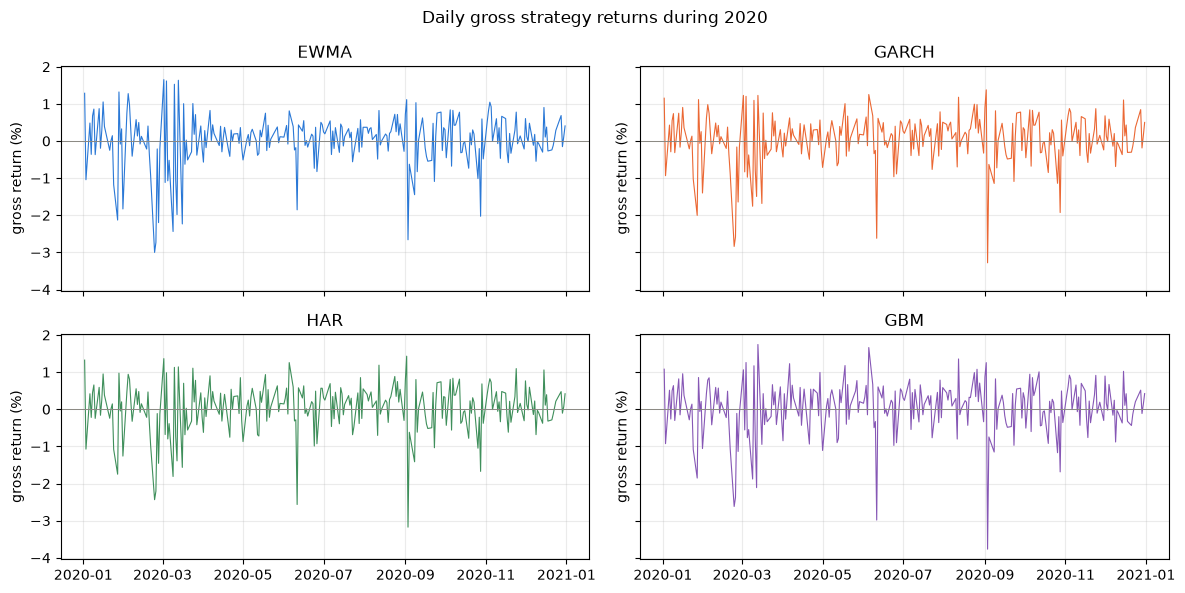

In [3]:
zoom = gross_returns.loc["2020"] * 100
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, name in zip(axes.flat, MODELS, strict=True):
    ax.plot(zoom.index, zoom[name], lw=0.8, color=COLORS[name])
    ax.axhline(0.0, lw=0.7, color="#898781")
    ax.set_title(name.upper())
    ax.set_ylabel("gross return (%)")
    ax.grid(alpha=0.25)
fig.suptitle("Daily gross strategy returns during 2020")
fig.tight_layout()
plt.show()

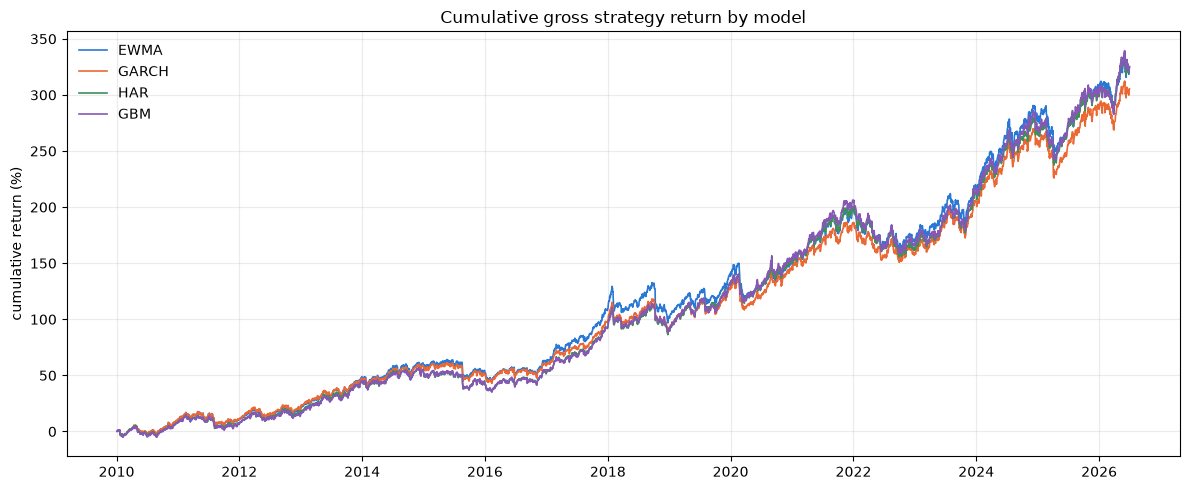

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
for name in MODELS:
    ax.plot(
        gross_values.index,
        (gross_values[name] - 1.0) * 100,
        lw=1.2,
        color=COLORS[name],
        label=name.upper(),
    )
ax.set_title("Cumulative gross strategy return by model")
ax.set_ylabel("cumulative return (%)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Portfolio state and trades

GBM provides a compact visual audit of the target, pre-trade drifted weight, held weight after the band decision, trade days, and turnover.

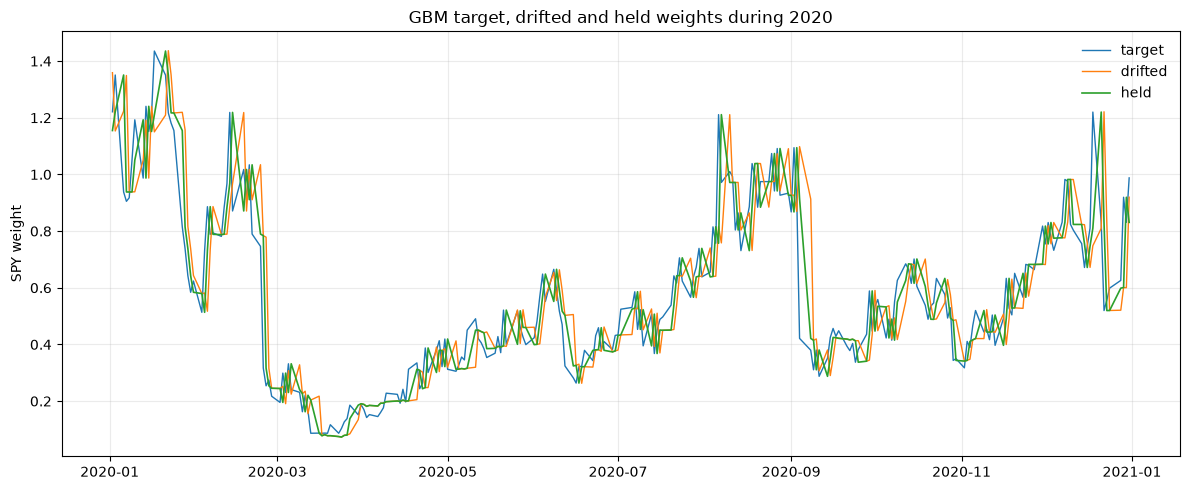

In [5]:
audit = model_ledgers["gbm"].loc["2020"]
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(audit.index, audit["target_weight"], lw=1.0, label="target")
ax.plot(audit.index, audit["drifted_weight"], lw=1.0, label="drifted")
ax.plot(audit.index, audit["held_weight"], lw=1.2, label="held")
ax.set_title("GBM target, drifted and held weights during 2020")
ax.set_ylabel("SPY weight")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [6]:
trade_days = audit.loc[
    audit["turnover"] > 0.0,
    [
        "return_weight",
        "drifted_weight",
        "held_weight",
        "turnover",
        "transaction_cost",
    ],
]
assert (trade_days["held_weight"] == trade_days["return_weight"]).all()
trade_days.head(10)

,return_weight,drifted_weight,held_weight,turnover,transaction_cost
date,,,,,
2020-01-02,1.154989,1.359185,1.154989,0.204196,0.000041
2020-01-03,1.221025,1.153394,1.221025,0.067631,0.000014
2020-01-06,1.350932,1.223126,1.350932,0.127805,0.000026
2020-01-07,0.938122,1.349204,0.938122,0.411082,0.000082
2020-01-10,1.050350,0.938723,1.050350,0.111627,0.000022
2020-01-13,1.192822,1.050530,1.192822,0.142292,0.000028
2020-01-14,0.987187,1.191305,0.987187,0.204119,0.000041
2020-01-15,1.240425,0.987207,1.240425,0.253218,0.000051
2020-01-16,1.151590,1.239840,1.151590,0.088250,0.000018


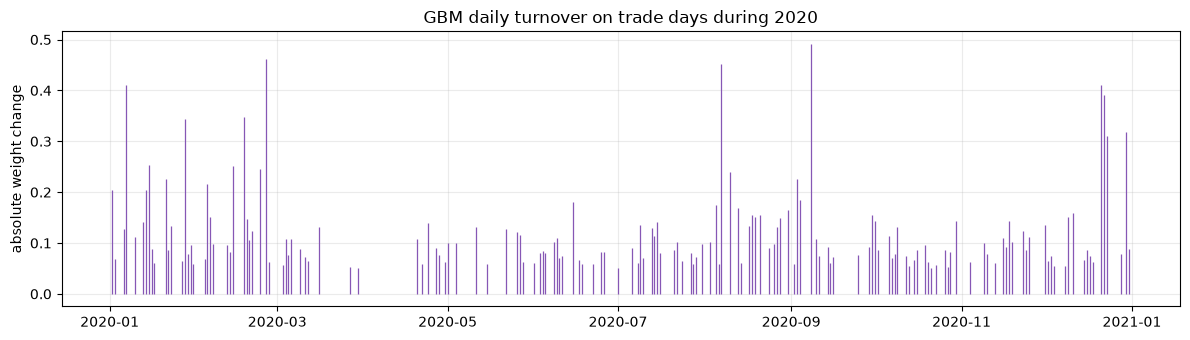

In [7]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.vlines(trade_days.index, 0.0, trade_days["turnover"], lw=0.9, color=COLORS["gbm"])
ax.set_title("GBM daily turnover on trade days during 2020")
ax.set_ylabel("absolute weight change")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

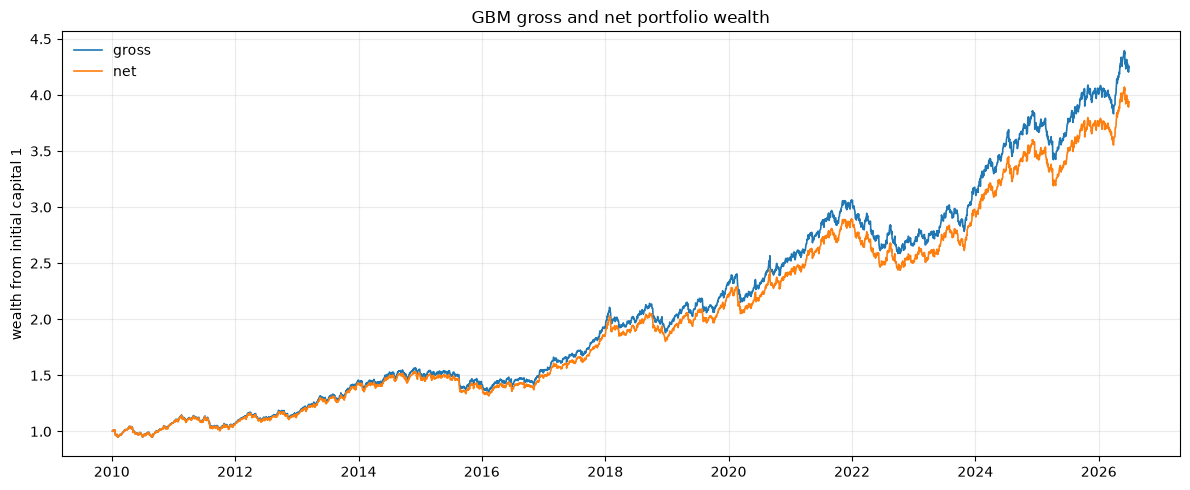

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(gross_values.index, gross_values["gbm"], lw=1.2, label="gross")
ax.plot(net_values.index, net_values["gbm"], lw=1.2, label="net")
ax.set_title("GBM gross and net portfolio wealth")
ax.set_ylabel("wealth from initial capital 1")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Headline timing and gross accounting

Synthetic forecasts generate known target weights while market returns and cash returns come from the canonical dataset.

In [9]:
config = BacktestConfig(apply_cap=False, initial_capital=100.0)
target_daily = config.target_vol_annual / sqrt(TRADING_DAYS)
desired_weights = pd.Series(
    np.resize([0.5, 1.0, 2.0], len(dates)),
    index=dates,
)
forecasts = target_daily / desired_weights
ledger = build_ledger(market, forecasts, config).iloc[1:]
executed_weights = desired_weights.shift(1).iloc[1:]

spread_daily = (1.0 + config.funding_spread_annual) ** (1.0 / TRADING_DAYS) - 1.0
expected_cash = pd.Series(
    np.where(
        executed_weights <= 1.0,
        (1.0 - executed_weights) * ledger["rf"],
        -(executed_weights - 1.0) * (ledger["rf"] + spread_daily),
    ),
    index=ledger.index,
)
expected_gross = executed_weights * ledger["return_close_to_close"] + expected_cash
expected_value = config.initial_capital * (1.0 + expected_gross).cumprod()

assert np.allclose(ledger["raw_weight"], desired_weights.iloc[1:])
assert np.allclose(ledger["return_weight"], executed_weights)
assert np.allclose(ledger["cash_contribution"], expected_cash)
assert np.allclose(ledger["gross_return"], expected_gross)
assert np.allclose(ledger["portfolio_value_gross"], expected_value)

ledger[
    [
        "forecast_vol",
        "target_weight",
        "drifted_weight",
        "held_weight",
        "turnover",
        "transaction_cost",
        "gross_return",
        "net_return",
        "portfolio_value_gross",
        "portfolio_value_net",
    ]
]

,forecast_vol,target_weight,drifted_weight,held_weight,turnover,transaction_cost,gross_return,net_return,portfolio_value_gross,portfolio_value_net
date,,,,,,,,,,
2020-01-06,0.006299,1.0,0.000000,0.5,0.500000,0.000100,0.001937,0.001837,100.193742,100.183742
2020-01-07,0.003150,2.0,0.500987,1.0,0.499013,0.000100,-0.002812,-0.002911,99.912036,99.892065
2020-01-08,0.012599,0.5,1.000100,2.0,0.999900,0.000200,0.010579,0.010379,100.968986,100.928828
2020-01-09,0.006299,1.0,1.990005,0.5,1.490005,0.000298,0.003421,0.003123,101.314352,101.243980
2020-01-10,0.003150,2.0,0.501823,1.0,0.498177,0.000100,-0.002878,-0.002977,101.022806,100.942548
2020-01-13,0.012599,0.5,1.000100,2.0,0.999900,0.000200,0.013674,0.013474,102.404188,102.302646
2020-01-14,0.006299,1.0,1.986982,0.5,1.486982,0.000297,-0.000731,-0.001029,102.329286,102.197394
2020-01-15,0.003150,2.0,0.499752,1.0,0.500248,0.000100,0.002260,0.002160,102.560561,102.418147


## Leverage cap

The cap changes target weights without changing raw weights.

In [10]:
capped_config = replace(config, apply_cap=True)
capped = build_ledger(market, forecasts, capped_config)

assert np.allclose(capped["raw_weight"], desired_weights)
assert capped["target_weight"].max() == capped_config.max_weight
assert (capped["target_weight"] <= capped_config.max_weight).all()

capped[["raw_weight", "target_weight", "return_weight"]]

,raw_weight,target_weight,return_weight
date,,,
2020-01-03,0.5,0.5,NaN
2020-01-06,1.0,1.0,0.5
2020-01-07,2.0,1.5,1.0
2020-01-08,0.5,0.5,1.5
2020-01-09,1.0,1.0,0.5
2020-01-10,2.0,1.5,1.0
2020-01-13,0.5,0.5,1.5
2020-01-14,1.0,1.0,0.5
2020-01-15,2.0,1.5,1.0


## No-lag counterfactual

With `execution_lag=0`, the next target-dated weight moves back one row. The unavailable final row remains `NaN` and is not capitalized.

In [11]:
counterfactual_config = replace(config, execution_lag=0)
counterfactual = build_ledger(market, forecasts, counterfactual_config)

assert np.allclose(
    counterfactual["return_weight"].iloc[:-1],
    desired_weights.shift(-1).iloc[:-1],
)
assert (
    counterfactual.iloc[-1][
        [
            "return_weight",
            "spy_contribution",
            "cash_contribution",
            "gross_return",
            "net_return",
            "portfolio_value_gross",
            "portfolio_value_net",
        ]
    ]
    .isna()
    .all()
)

counterfactual[
    ["target_weight", "return_weight", "held_weight", "gross_return", "net_return"]
].tail()

,target_weight,return_weight,held_weight,gross_return,net_return
date,,,,,
2020-01-09,1.0,2.0,2.0,0.013480,0.013280
2020-01-10,2.0,0.5,0.5,-0.001408,-0.001706
2020-01-13,0.5,1.0,1.0,0.006877,0.006777
2020-01-14,1.0,2.0,2.0,-0.003131,-0.003331
2020-01-15,2.0,NaN,NaN,NaN,NaN


This check intentionally excludes weekly and monthly decision frequencies, sensitivity runs, and strategy evaluation metrics.